In [3]:

# 1. Importer les bibliothèques
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Charger les données
df = pd.read_csv("all_data.csv")

# 3. Afficher les premières lignes
print(df.head())


# Dimensions du tableau
print(df.shape)

# Noms des colonnes
print(df.columns)





  Country  Year  Life expectancy at birth (years)           GDP
0   Chile  2000                              77.3  7.786093e+10
1   Chile  2001                              77.3  7.097992e+10
2   Chile  2002                              77.8  6.973681e+10
3   Chile  2003                              77.9  7.564346e+10
4   Chile  2004                              78.0  9.921039e+10
(96, 4)
Index(['Country', 'Year', 'Life expectancy at birth (years)', 'GDP'], dtype='str')


# Espérance de vie et PIB

## 1. Objectif du projet

L’objectif de ce projet est d’analyser la relation entre le produit intérieur brut (PIB) et l’espérance de vie dans six pays.

## 2. Questions de recherche

- Existe-t-il une relation entre le PIB et l’espérance de vie ?
- Les pays ayant un PIB plus élevé ont-ils une espérance de vie plus élevée ?
- Comment l’espérance de vie a-t-elle évolué au fil du temps dans chaque pays ?

## 3. Données

Le jeu de données `all_data.csv` contient des informations sur le PIB et l’espérance de vie de six pays sur plusieurs années.

## 4. Plan d’analyse

- Charger et examiner le jeu de données.
- Nettoyer et préparer les données si nécessaire.
- Calculer des statistiques descriptives.
- Étudier la relation entre le PIB et l’espérance de vie.
- Créer des visualisations à l’aide de Pandas, Matplotlib et Seaborn.
- Interpréter les résultats et rédiger une conclusion.

In [4]:


# 2. Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(df.isnull().sum())

# 3. Afficher les statistiques descriptives
print("\nStatistiques descriptives :")
print(df.describe())

# 4. Identifier les six pays
print("\nPays étudiés :")
print(df["Country"].unique())

# 5. Vérifier les années étudiées
print("\nAnnées étudiées :")
print(df["Year"].min(), "-", df["Year"].max())


Valeurs manquantes :
Country                             0
Year                                0
Life expectancy at birth (years)    0
GDP                                 0
dtype: int64

Statistiques descriptives :
              Year  Life expectancy at birth (years)           GDP
count    96.000000                         96.000000  9.600000e+01
mean   2007.500000                         72.789583  3.880499e+12
std       4.633971                         10.672882  5.197561e+12
min    2000.000000                         44.300000  4.415703e+09
25%    2003.750000                         74.475000  1.733018e+11
50%    2007.500000                         76.750000  1.280220e+12
75%    2011.250000                         78.900000  4.067510e+12
max    2015.000000                         81.000000  1.810000e+13

Pays étudiés :
<ArrowStringArray>
['Chile', 'China', 'Germany', 'Mexico', 'United States of America',
 'Zimbabwe']
Length: 6, dtype: str

Années étudiées :
2000 - 2015


Interprétation de tes résultats
96 observations et 4 colonnes
Les données couvrent six pays sur la période 2000–2015.
Aucune valeur manquante
Les quatre colonnes affichent zéro valeur manquante. C'est un bon point pour la qualité des données.
Espérance de vie moyenne : 72,79 ans
Le minimum observé est de 44,3 ans et le maximum de 81 ans.

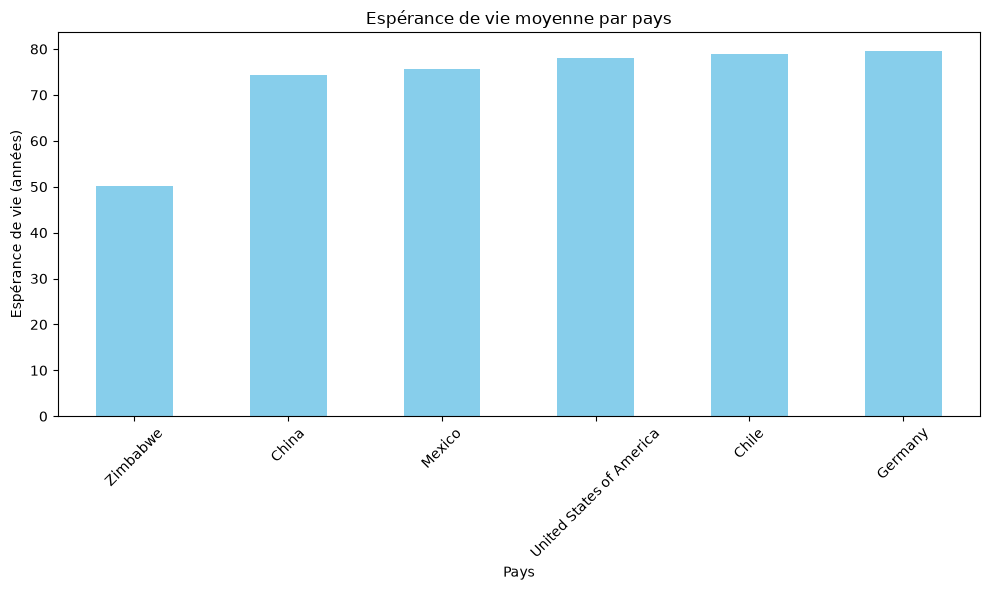

In [5]:
# Espérance de vie moyenne par pays

life_expectancy = df.groupby("Country")[
    "Life expectancy at birth (years)"
].mean().sort_values()

plt.figure(figsize=(10, 6))

life_expectancy.plot(kind="bar", color="skyblue")

plt.title("Espérance de vie moyenne par pays")
plt.xlabel("Pays")
plt.ylabel("Espérance de vie (années)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Interprétation du graphique : espérance de vie moyenne par pays

Le graphique montre des différences importantes d'espérance de vie moyenne entre les six pays étudiés sur la période 2000-2015. L'Allemagne et le Chili présentent les moyennes les plus élevées, tandis que le Zimbabwe affiche la moyenne la plus faible. La Chine, le Mexique et les États-Unis se situent entre ces deux groupes.

Ces différences méritent d'être approfondies en étudiant l'évolution de l'espérance de vie dans le temps et sa relation avec le produit intérieur brut (PIB). Ce graphique seul ne permet pas d'expliquer les causes de ces écarts.

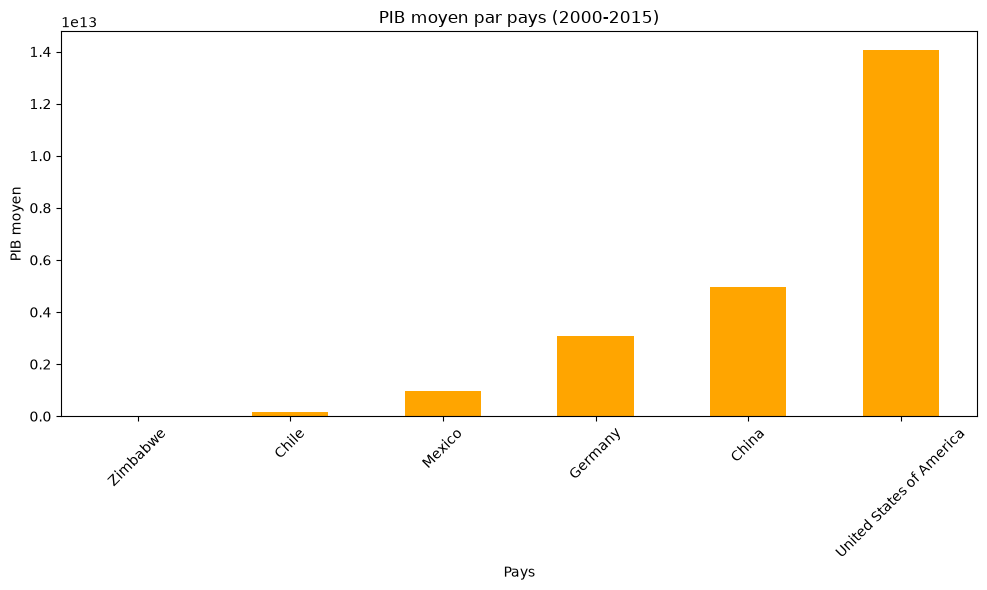

In [6]:
# Calculer le PIB moyen par pays
gdp_by_country = df.groupby("Country")["GDP"].mean().sort_values()

# Créer le graphique
plt.figure(figsize=(10, 6))
gdp_by_country.plot(kind="bar", color="orange")

plt.title("PIB moyen par pays (2000-2015)")
plt.xlabel("Pays")
plt.ylabel("PIB moyen")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

nterprétation du graphique : PIB moyen par pays

Le graphique met en évidence des différences importantes de PIB moyen entre les six pays étudiés entre 2000 et 2015. Les États-Unis présentent le PIB moyen le plus élevé, tandis que le Zimbabwe affiche le plus faible. L'Allemagne et la Chine occupent également une place importante, alors que le Mexique présente un PIB moyen inférieur à celui des grandes économies étudiées.

Ces résultats montrent que les niveaux de production économique varient considérablement d'un pays à l'autre. Toutefois, le PIB total ne permet pas, à lui seul, de mesurer le niveau de vie de la population. Il est donc nécessaire d'examiner également la relation entre le PIB et l'espérance de vie pour mieux comprendre les différences observées.

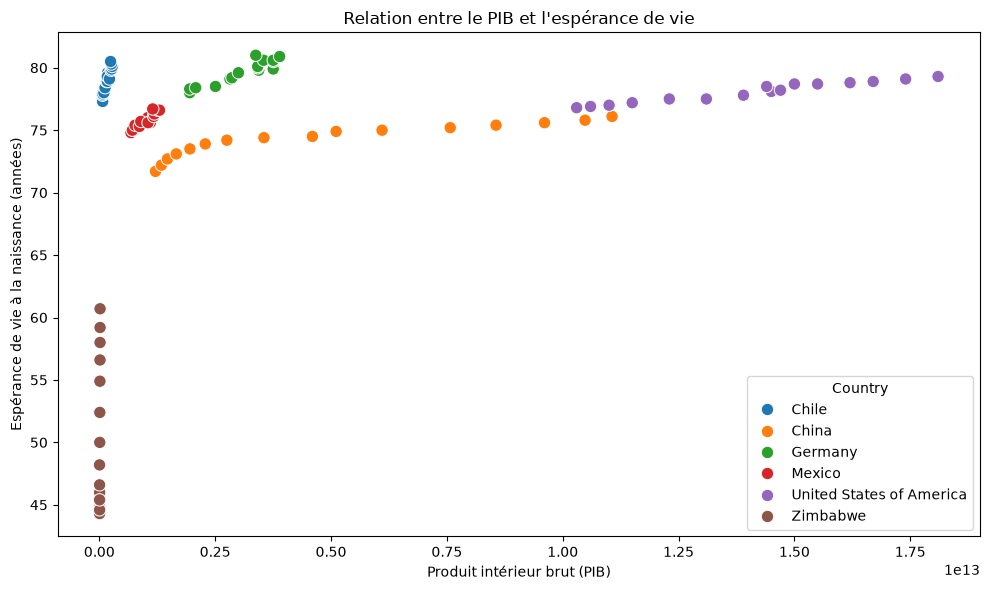

In [7]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GDP",
    y="Life expectancy at birth (years)",
    hue="Country",
    s=80
)

plt.title("Relation entre le PIB et l'espérance de vie")
plt.xlabel("Produit intérieur brut (PIB)")
plt.ylabel("Espérance de vie à la naissance (années)")
plt.tight_layout()
plt.show()

Interprétation du graphique : relation entre le PIB et l'espérance de vie

Le nuage de points permet d'examiner la relation entre le produit intérieur brut (PIB) et l'espérance de vie à la naissance dans six pays entre 2000 et 2015.

Les observations suggèrent des différences entre les pays. Les États-Unis présentent des valeurs de PIB particulièrement élevées, tandis que le Zimbabwe se situe à des niveaux de PIB et d'espérance de vie plus faibles. D'autres pays, comme la Chine, l'Allemagne et le Mexique, présentent des profils différents.

Cependant, le graphique seul ne suffit pas à établir précisément la force de la relation entre le PIB et l'espérance de vie. Une analyse complémentaire de l'évolution dans le temps et de la corrélation entre ces deux variables permettra d'approfondir cette observation.

Conclusion générale

Dans ce projet, nous avons analysé la relation entre le produit intérieur brut (PIB) et l'espérance de vie à la naissance dans six pays : le Chili, la Chine, l'Allemagne, le Mexique, les États-Unis et le Zimbabwe, sur la période 2000-2015.

L'exploration des données a révélé que le jeu de données contient 96 observations et quatre colonnes, sans valeurs manquantes. Les statistiques descriptives indiquent une espérance de vie moyenne d'environ 72,79 ans, avec des valeurs allant de 44,3 à 81 ans.

La comparaison entre les pays a mis en évidence des différences importantes. L'Allemagne et le Chili présentent les espérances de vie moyennes les plus élevées, tandis que le Zimbabwe affiche la moyenne la plus faible. L'analyse du PIB moyen montre également des écarts économiques considérables, les États-Unis ayant le PIB moyen le plus élevé parmi les pays étudiés.

Le nuage de points permet de comparer le PIB et l'espérance de vie, mais les graphiques réalisés ne suffisent pas, à eux seuls, à mesurer précisément la force de leur relation ni à démontrer un lien de causalité.

En conclusion, ce projet a permis de découvrir des différences économiques et sanitaires entre les six pays et de mettre en pratique les techniques d'exploration, de préparation et de visualisation des données avec Python, Pandas, Matplotlib et Seaborn. Une analyse complémentaire de la corrélation et de l'évolution des variables dans le temps permettrait d'approfondir les résultats.

PIB et espérance de vie : que nous apprennent les données de six pays ?

Introduction

Le développement économique et la santé des populations sont deux dimensions importantes du développement d'un pays. Mais un pays dont l'économie est plus importante offre-t-il nécessairement une espérance de vie plus élevée à sa population ?

Pour explorer cette question, nous avons analysé les données du produit intérieur brut (PIB) et de l'espérance de vie à la naissance de six pays : le Chili, la Chine, l'Allemagne, le Mexique, les États-Unis et le Zimbabwe, entre 2000 et 2015.

Méthodologie

L'analyse a été réalisée à partir du fichier "all_data.csv". Nous avons utilisé Python et les bibliothèques Pandas, Matplotlib et Seaborn pour examiner les données, calculer des statistiques descriptives et créer des visualisations.

Le jeu de données contient 96 observations et quatre variables : le pays, l'année, l'espérance de vie à la naissance et le PIB. La vérification initiale n'a révélé aucune valeur manquante.

Nous avons ensuite comparé l'espérance de vie moyenne et le PIB moyen des six pays, puis créé un nuage de points afin d'examiner la relation entre ces deux variables.

Des différences importantes d'espérance de vie

Les résultats montrent que l'espérance de vie moyenne varie considérablement selon les pays. L'Allemagne et le Chili figurent parmi les pays présentant les moyennes les plus élevées, tandis que le Zimbabwe présente la moyenne la plus faible.

L'espérance de vie moyenne de l'ensemble des observations est d'environ 72,79 ans. Les valeurs observées vont de 44,3 à 81 ans.

Ces écarts soulignent l'existence de situations différentes entre les pays étudiés. Toutefois, les graphiques descriptifs ne permettent pas, à eux seuls, d'expliquer les causes de ces différences.

Des écarts économiques considérables

La comparaison du PIB moyen met en évidence des différences importantes entre les six économies. Les États-Unis présentent le PIB moyen le plus élevé dans ce jeu de données, tandis que le Zimbabwe affiche le plus faible.

Il faut cependant interpréter ces résultats avec prudence : le PIB total mesure la valeur de la production économique d'un pays. Il ne représente pas directement le revenu moyen de chaque habitant ni la qualité des services de santé accessibles à la population.

PIB et espérance de vie : quelle relation ?

Le nuage de points permet de visualiser simultanément le PIB et l'espérance de vie pour les différents pays et les différentes années.

Les observations montrent des profils différents selon les pays. Néanmoins, les graphiques réalisés ne suffisent pas à quantifier précisément la relation entre les deux variables. Il serait nécessaire de calculer leur corrélation et d'étudier leur évolution dans le temps pour déterminer plus précisément si elles varient ensemble.

Par ailleurs, une association entre le PIB et l'espérance de vie ne prouverait pas que l'augmentation du PIB entraîne automatiquement une hausse de l'espérance de vie. D'autres facteurs, comme l'accès aux soins, l'éducation, les conditions de vie et les inégalités, peuvent également intervenir.

Conclusion

Cette analyse met en évidence des différences économiques et sanitaires entre les six pays étudiés. Elle montre l'intérêt de la visualisation des données pour comparer des situations nationales et formuler des questions de recherche.

L'étude constitue une première étape dans la compréhension des liens entre développement économique et santé. Des analyses statistiques complémentaires permettraient de mieux mesurer la relation entre le PIB et l'espérance de vie et d'examiner les facteurs susceptibles d'expliquer les différences observées.

Ce projet m'a également permis de mettre en pratique les outils Python utilisés en science des données, depuis le chargement et l'exploration des données jusqu'à la création de graphiques et à la communication des résultats.